In [130]:
# Zipf's Law: The Jungle Book (corpus 2)

In [131]:
from urllib.request import urlopen
from collections import Counter
import matplotlib.pyplot as plt
import string

In [132]:
# Corpus URL
url = "https://raw.githubusercontent.com/coli-saar/cl/main/a1/junglebook.txt"
text = urlopen(url).read().decode("utf-8")
text = text.lower()

The corpus was converted to lowercase to avoid counting uppercase and lowercase forms as different words.

In [133]:
# Word counting 1: remove punctuation; apostrophes preserved
punctuation_with_apo = string.punctuation.replace("'", "")

text_keep = text

for p in punctuation_with_apo:
    text_keep = text_keep.replace(p, " ")

Punctuation marks were removed while preserving apostrophes, and tokenization was performed by splitting the text at whitespace.

In [134]:
# Tokens and frequencies of each unique word
words_keep = text_keep.split()
print("Number of words:", len(words_keep))
freq_keep = Counter(words_keep)

# Sort words by descending frequency
sorted_keep = freq_keep.most_common()

frequencies_keep = [count for word, count in sorted_keep]
ranks_keep = range(1, len(frequencies_keep) + 1)

# Preview: the 20 most frequent words
print("Top 20 most frequent words:\n")
for word, count in sorted_keep[:20]:
    print(word, count)

Number of words: 56220
Top 20 most frequent words:

the 3729
and 2355
of 1348
to 1288
a 1173
he 1081
in 747
that 666
his 659
i 609
was 536
for 467
is 465
said 442
with 436
as 426
it 392
they 382
on 379
him 373


Word frequencies were then computed and sorted in descending order. The resulting rank-frequency distribution was used for the subsequent analysis.

In [135]:
# Word counting 2: remove all punctuation marks
text_split = text

for p in string.punctuation:
    text_split = text_split.replace(p, " ")

The same procedure was repeated after removing all punctuation marks, including apostrophes, in order to compare the effect of the two tokenization strategies.

In [136]:
# Tokens and frequencies of each unique word
words_split = text_split.split()
print("Number of words:", len(words_split))
freq_split = Counter(words_split)

# Sort words by descending frequency
sorted_split = freq_split.most_common()

frequencies_split = [count for word, count in sorted_split]
ranks_split = range(1, len(frequencies_split) + 1)

# Preview: the 20 most frequent words
print("Top 20 most frequent words:\n")
for word, count in sorted_split[:20]:
    print(word, count)

Number of words: 56806
Top 20 most frequent words:

the 3731
and 2355
of 1348
to 1290
a 1173
he 1097
in 747
that 683
his 659
i 658
was 536
for 467
is 466
said 442
with 436
as 427
it 411
s 404
they 387
on 379


Word frequencies were then computed and sorted in descending order. The resulting rank-frequency distribution was used for the subsequent analysis.

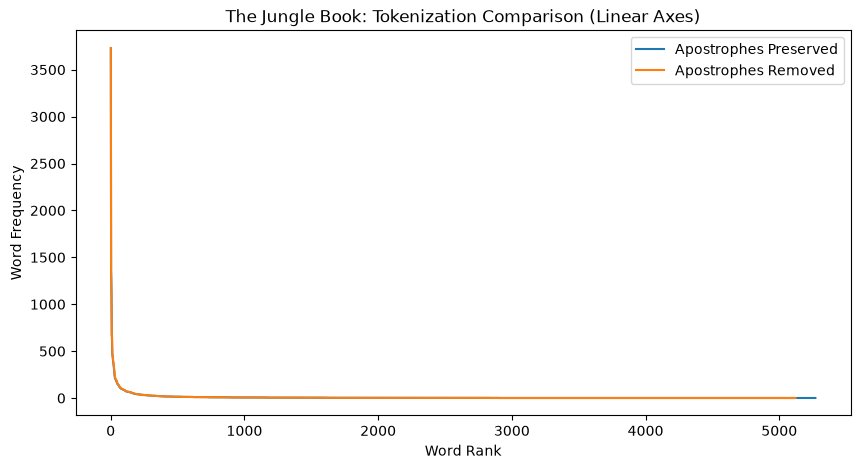

In [137]:
# Linear comparison
plt.figure(figsize=(10,5))

plt.plot(
    ranks_keep,
    frequencies_keep,
    label="Apostrophes Preserved"
)

plt.plot(
    ranks_split,
    frequencies_split,
    label="Apostrophes Removed"
)

plt.xlabel("Word Rank")
plt.ylabel("Word Frequency")
plt.title("The Jungle Book: Tokenization Comparison (Linear Axes)")

plt.legend()

plt.show()

A linear plot was created to compare the two rank-frequency distributions.

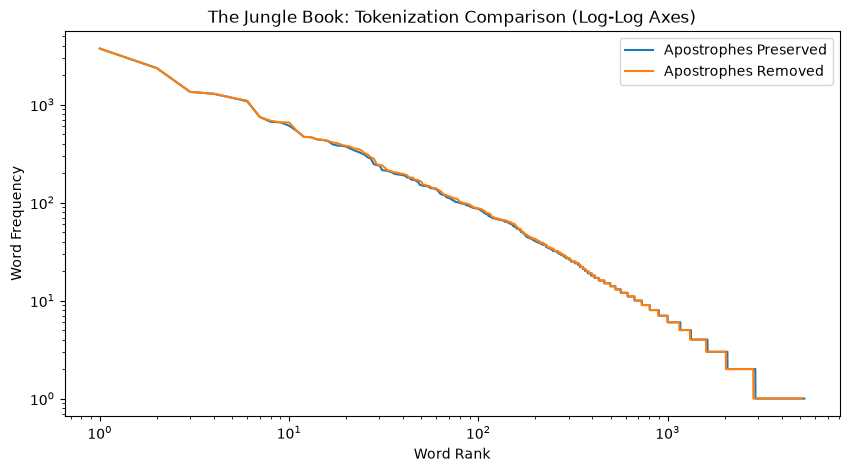

In [138]:
# Log-log comparison
plt.figure(figsize=(10,5))

plt.loglog(
    ranks_keep,
    frequencies_keep,
    label="Apostrophes Preserved"
)

plt.loglog(
    ranks_split,
    frequencies_split,
    label="Apostrophes Removed"
)

plt.xlabel("Word Rank")
plt.ylabel("Word Frequency")
plt.title("The Jungle Book: Tokenization Comparison (Log-Log Axes)")

plt.legend()

plt.show()

A log-log plot was created to compare the two rank-frequency distributions.

In the linear plot, word frequencies decrease rapidly: a small number of words occur very frequently, while most words occur relatively rarely.
The log-log plot appears approximately linear over a large range of ranks. Overall, the corpus exhibits the typical Zipfian distribution, according to which word frequency decreases approximately inversely with rank. A simple illustration of this can be seen by examining the 20 most frequent words in the corpus, which are predominantly function words such as articles, pronouns, prepositions, conjunctions, and auxiliary verbs.

Some contracted forms are present in this corpus. In addition, there are 404 occurrences of the morpheme "s" (the 18th most frequent token), marking the Saxon genitive. 
An additional comparison was conducted to examine the effect of apostrophe treatment on the Zipfian distribution.

When apostrophes were preserved ("keep"), forms such as "Khan's" remained single tokens. When apostrophes were replaced with whitespace ("split"), these forms were separated into the tokens "Khan" and "s", therefore introducing additional tokens.

Despite the introduction of the high-frequency token "s" and additional tokens derived from contracted forms in the second strategy, the resulting Zipf curves are almost identical. This suggests that the overall rank-frequency distribution is largely robust to this particular tokenization choice.